# TUẦN 3 (BUỔI 3) — BÀI TẬP NOTEBOOK 1–7
**Đặng Văn Chung — 24174800194 — DHKM18A2HN**

## Chuẩn bị chung
### Bước 1. Kiểm tra thư viện sampling

In [1]:
import importlib.util
import subprocess
import sys
import os

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

### Bước 2. Import thư viện xử lý dữ liệu và đánh giá

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

**Hiển thị đủ cột trong bảng:**

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.expand_frame_repr", False)

### Bước 3. Import các mô hình cần thử

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

### Bước 4. Nạp dữ liệu và đổi nhãn

In [5]:
cancer = load_breast_cancer(as_frame=True)
df_full = cancer.data.copy()
df_full["target"] = (cancer.target == 0).astype(int)
print(df_full["target"].value_counts().sort_index())

target
0    357
1    212
Name: count, dtype: int64


### Bước 5. Tạo hàm lấy số malignant cần dùng
`None` nghĩa là giữ toàn bộ malignant. Benign luôn được giữ nguyên.

In [6]:
def make_data(n_malignant=60):
    benign = df_full[df_full["target"] == 0]
    malignant = df_full[df_full["target"] == 1]
    if n_malignant is not None:
        malignant = malignant.sample(n=n_malignant, random_state=RANDOM_STATE)
    frame = pd.concat([benign, malignant])
    return frame.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

### Bước 6. Tạo hàm chia Train/Test

In [7]:
def split_data(frame):
    return train_test_split(
        frame.drop(columns="target"), frame["target"],
        test_size=0.2, stratify=frame["target"], random_state=RANDOM_STATE
    )

### Bước 7. Khai báo các chỉ số chấm điểm

In [8]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "pr_auc": "average_precision"
}

### Bước 8. Tạo hàm ghép pipeline
Thứ tự: scaler → sampling (nếu có) → classifier. CV sẽ học lại pipeline trong từng fold.

In [9]:
def build_pipeline(model=None, sampler=None, scale=True):
    if model is None:
        model = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    steps = [("scaler", StandardScaler() if scale else "passthrough")]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", clone(model)))
    return Pipeline(steps)

### Bước 9. Tạo hàm chia StratifiedKFold

In [10]:
def get_cv(k=5):
    return StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

### Bước 10. Tạo hàm chạy CV và tính mean/std

In [11]:
def evaluate_cv(pipe, X_data, y_data, cv):
    scores = cross_validate(
        pipe, X_data, y_data, cv=cv, scoring=scoring,
        error_score="raise", n_jobs=1
    )
    fold_scores = pd.DataFrame({m: scores["test_" + m] for m in scoring})
    summary = {}
    for metric in scoring:
        summary[metric + "_mean"] = fold_scores[metric].mean()
        summary[metric + "_std"] = fold_scores[metric].std(ddof=1)
    return summary, fold_scores

### Bước 11. Tạo hàm hiển thị bảng mean ± std

In [12]:
def show_scores(results, metrics=None):
    if metrics is None:
        metrics = list(scoring)
    table = pd.DataFrame(index=results.index)
    for metric in metrics:
        table[metric + " (mean ± std)"] = results.apply(
            lambda r: f"{r[metric + '_mean']:.4f} ± {r[metric + '_std']:.4f}", axis=1
        )
    display(table)

### Bước 12. Chuẩn bị dữ liệu dùng chung cho Bài 2–6

In [13]:
frame = make_data(60)
X_train, X_test, y_train, y_test = split_data(frame)
folds5 = list(get_cv(5).split(X_train, y_train))
print("Train:", y_train.value_counts().sort_index().to_dict())
print("Test:", y_test.value_counts().sort_index().to_dict())

Train: {0: 285, 1: 48}
Test: {0: 72, 1: 12}


## Bài 1. Mức độ imbalance
### Bước 1. Khai báo các mức cần thử
Giữ 60 làm mốc; ba mức còn lại là yêu cầu của đề.

In [14]:
levels = [40, 60, 120, None]

### Bước 2. Chạy Logistic Regression cho từng mức
Mỗi mức dùng StandardScaler, không sampling và CV 5 fold trên Train.

In [15]:
rows = []
for n in levels:
    data = make_data(n)
    Xtr, Xte, ytr, yte = split_data(data)
    row, _ = evaluate_cv(build_pipeline(), Xtr, ytr, get_cv(5))
    name = "Gốc (212 malignant)" if n is None else f"{n} malignant"
    rows.append({"Mức dữ liệu": name, **row})

### Bước 3. Xem bảng so sánh

In [16]:
result1 = pd.DataFrame(rows).set_index("Mức dữ liệu")
show_scores(result1, ["accuracy", "recall", "f1", "pr_auc"])

,accuracy (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
Mức dữ liệu,,,,
40 malignant,0.9938 ± 0.0086,0.9429 ± 0.0782,0.9692 ± 0.0421,0.9754 ± 0.0363
60 malignant,0.9850 ± 0.0183,0.9400 ± 0.1342,0.9447 ± 0.0722,0.9855 ± 0.0325
120 malignant,0.9711 ± 0.0216,0.9274 ± 0.0274,0.9432 ± 0.0388,0.9882 ± 0.0147
Gốc (212 malignant),0.9758 ± 0.0120,0.9529 ± 0.0446,0.9668 ± 0.0176,0.9939 ± 0.0054


**Nhận xét:** 40 malignant có Accuracy cao nhất (0.9938), nhưng dữ liệu gốc có Recall 0.9529 và AP 0.9939. Các mức đồng thời thay đổi số mẫu và tỷ lệ lớp; không kết luận chỉ từ Accuracy hoặc quy toàn bộ khác biệt AP cho imbalance.

## Bài 2. KFold và StratifiedKFold
### Bước 1. Tạo hai cách chia, cùng K=5

In [17]:
cv_options = {
    "KFold": KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    "StratifiedKFold": get_cv(5)
}

### Bước 2. Chạy cùng Logistic Regression

In [18]:
rows = []
for name, cv in cv_options.items():
    row, _ = evaluate_cv(build_pipeline(), X_train, y_train, cv)
    rows.append({"CV": name, **row})

### Bước 3. Xem mean và std

In [19]:
result2 = pd.DataFrame(rows).set_index("CV")
show_scores(result2)

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
CV,,,,,
KFold,0.9880 ± 0.0125,1.0000 ± 0.0000,0.9012 ± 0.1177,0.9446 ± 0.0685,0.9891 ± 0.0210
StratifiedKFold,0.9850 ± 0.0183,0.9618 ± 0.0524,0.9400 ± 0.1342,0.9447 ± 0.0722,0.9855 ± 0.0325


### Bước 4. Kiểm tra số malignant trong mỗi validation fold

In [20]:
for name, cv in cv_options.items():
    counts = []
    for _, val_idx in cv.split(X_train, y_train):
        counts.append(int(y_train.iloc[val_idx].sum()))
    print(name, ":", counts)

KFold : [7, 10, 12, 11, 8]
StratifiedKFold : [10, 10, 10, 9, 9]


**Nhận xét:** Recall của KFold là 0.9012 ± 0.1177; StratifiedKFold là 0.9400 ± 0.1342. StratifiedKFold phân bổ lớp đều hơn, nhưng std của metric ở lần chia này không thấp hơn. Không viết “StratifiedKFold luôn ổn định hơn trên mọi chỉ số”.

## Bài 3. Thay số fold
### Bước 1. Khai báo K

In [21]:
k_values = [3, 5, 10]

### Bước 2. Chạy CV cho từng K
Giữ nguyên dữ liệu và pipeline của Bài 2.

In [22]:
rows = []
for k in k_values:
    row, _ = evaluate_cv(build_pipeline(), X_train, y_train, get_cv(k))
    rows.append({"K": k, **row})

### Bước 3. Xem bảng mean/std

In [23]:
result3 = pd.DataFrame(rows).set_index("K")
show_scores(result3)

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
K,,,,,
3,0.9880 ± 0.0052,1.0000 ± 0.0000,0.9167 ± 0.0361,0.9563 ± 0.0199,0.9907 ± 0.0162
5,0.9850 ± 0.0183,0.9618 ± 0.0524,0.9400 ± 0.1342,0.9447 ± 0.0722,0.9855 ± 0.0325
10,0.9880 ± 0.0155,0.9667 ± 0.0703,0.9550 ± 0.0956,0.9564 ± 0.0580,0.9861 ± 0.0439


**Nhận xét:** K=3, 5, 10 có F1 lần lượt 0.9563 ± 0.0199; 0.9447 ± 0.0722; 0.9564 ± 0.0580. K tăng không làm std giảm đều. Với 48 malignant trong Train, K=10 chỉ có 4–5 malignant ở mỗi validation fold nên Recall dễ dao động.

## Bài 4. Thay mức Over-Sampling
### Bước 1. Khai báo tỷ lệ cần thử
Tỷ lệ là số minority/majority sau sampling, không phải tỷ lệ minority trên tổng mẫu.

In [24]:
ratios = [0.5, 0.75, 1.0]

### Bước 2. Chạy từng mức ROS
Giữ cùng Logistic Regression và cùng các fold.

In [25]:
rows = []
for ratio in ratios:
    sampler = RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE)
    pipe = build_pipeline(sampler=sampler)
    row, _ = evaluate_cv(pipe, X_train, y_train, folds5)
    rows.append({"sampling_strategy": ratio, **row})

### Bước 3. So sánh Precision, Recall, F1 và AP

In [26]:
result4 = pd.DataFrame(rows).set_index("sampling_strategy")
show_scores(result4, ["precision", "recall", "f1", "pr_auc"])

,precision (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
sampling_strategy,,,,
0.50,0.9618 ± 0.0524,0.9600 ± 0.0894,0.9577 ± 0.0460,0.9836 ± 0.0318
0.75,0.9618 ± 0.0524,0.9600 ± 0.0894,0.9577 ± 0.0460,0.9855 ± 0.0325
1.00,0.9418 ± 0.0532,0.9600 ± 0.0894,0.9472 ± 0.0394,0.9855 ± 0.0325


**Nhận xét:** 0.5 và 0.75 cùng Precision 0.9618, Recall 0.9600, F1 0.9577. Mức 1.0 giảm Precision còn 0.9418, Recall không đổi. Tăng sampling có thể tăng phát hiện lớp dương nhưng cũng tăng báo động nhầm; kết quả không bắt buộc thay đổi đơn điệu.

## Bài 5. So sánh ba kỹ thuật sampling
### Bước 1. Tạo các sampler
Thêm trường hợp không sampling làm mốc; ba sampler dùng tỷ lệ mặc định 1:1.

In [27]:
samplers = {
    "No Sampling": None,
    "Random Over-Sampling": RandomOverSampler(random_state=RANDOM_STATE),
    "Random Under-Sampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE)
}

### Bước 2. Chạy cùng Logistic Regression

In [28]:
rows = []
for name, sampler in samplers.items():
    pipe = build_pipeline(sampler=sampler)
    row, _ = evaluate_cv(pipe, X_train, y_train, folds5)
    rows.append({"Sampling": name, **row})

### Bước 3. Xem bảng theo F1 giảm dần

In [29]:
result5 = pd.DataFrame(rows).set_index("Sampling")
show_scores(result5.sort_values("f1_mean", ascending=False))

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
Sampling,,,,,
SMOTE,0.9880 ± 0.0125,0.9618 ± 0.0524,0.9600 ± 0.0894,0.9577 ± 0.0460,0.9836 ± 0.0318
Random Under-Sampling,0.9849 ± 0.0107,0.9255 ± 0.0767,0.9800 ± 0.0447,0.9494 ± 0.0354,0.9895 ± 0.0234
Random Over-Sampling,0.9850 ± 0.0106,0.9418 ± 0.0532,0.9600 ± 0.0894,0.9472 ± 0.0394,0.9855 ± 0.0325
No Sampling,0.9850 ± 0.0183,0.9618 ± 0.0524,0.9400 ± 0.1342,0.9447 ± 0.0722,0.9855 ± 0.0325


### Bước 4. Chọn theo tiêu chí F1 CV

In [30]:
best_sampling = result5["f1_mean"].idxmax()
print("Sampling được chọn:", best_sampling)

Sampling được chọn: SMOTE


**Nhận xét:** SMOTE có F1 cao nhất (0.9577). RUS có Recall 0.9800 và AP 0.9895, cao nhất trong nhóm, nhưng Precision thấp hơn (0.9255). Chọn SMOTE theo F1 trong bài này; không kết luận SMOTE tốt nhất ở mọi chỉ số.

## Bài 6. Thay classifier
### Bước 1. Khai báo các mô hình

In [31]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM-RBF": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
}

### Bước 2. Chạy các classifier
Giữ StandardScaler + SMOTE và cùng các fold, chỉ thay mô hình.

In [32]:
rows = []
for name, clf in classifiers.items():
    pipe = build_pipeline(model=clf, sampler=SMOTE(random_state=RANDOM_STATE))
    row, _ = evaluate_cv(pipe, X_train, y_train, folds5)
    rows.append({"Classifier": name, **row})

### Bước 3. Xem kết quả

In [33]:
result6 = pd.DataFrame(rows).set_index("Classifier")
show_scores(result6.sort_values("f1_mean", ascending=False))

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),pr_auc (mean ± std)
Classifier,,,,,
Logistic Regression,0.9880 ± 0.0125,0.9618 ± 0.0524,0.9600 ± 0.0894,0.9577 ± 0.0460,0.9836 ± 0.0318
SVM-RBF,0.9880 ± 0.0125,0.9618 ± 0.0524,0.9600 ± 0.0894,0.9577 ± 0.0460,0.9807 ± 0.0431
KNN,0.9730 ± 0.0165,0.8833 ± 0.1118,0.9600 ± 0.0894,0.9128 ± 0.0532,0.9442 ± 0.0765
Decision Tree,0.9521 ± 0.0322,0.8107 ± 0.1467,0.9200 ± 0.0837,0.8538 ± 0.0836,0.8448 ± 0.0924


**Nhận xét:** Logistic Regression và SVM-RBF cùng F1 0.9577; KNN đạt 0.9128; Decision Tree độ sâu 4 đạt 0.8538. SVM dùng điểm `decision_function` khi tính AP.

### Bước 4. Kiểm tra riêng tác động của scaler
Để không lẫn tác động của scaler lên SMOTE, phép kiểm tra phụ giữ **ROS**, rồi bật/tắt scaler cho cùng classifier.

In [34]:
rows = []
for name, clf in classifiers.items():
    for use_scale in [False, True]:
        sampler = RandomOverSampler(random_state=RANDOM_STATE)
        pipe = build_pipeline(model=clf, sampler=sampler, scale=use_scale)
        row, _ = evaluate_cv(pipe, X_train, y_train, folds5)
        rows.append({"Classifier": name, "Scaler": use_scale, **row})

### Bước 5. So sánh F1 khi có và không có scaler

In [35]:
result_scale = pd.DataFrame(rows).set_index(["Classifier", "Scaler"])
scale_f1 = result_scale["f1_mean"].unstack("Scaler")
scale_f1.columns = ["F1 không scale", "F1 có scale"]
scale_f1["Chênh lệch F1"] = scale_f1["F1 có scale"] - scale_f1["F1 không scale"]
display(scale_f1.round(4))

,F1 không scale,F1 có scale,Chênh lệch F1
Classifier,,,
Decision Tree,0.8548,0.8548,0.0000
KNN,0.7832,0.9292,0.1459
Logistic Regression,0.8635,0.9472,0.0837
SVM-RBF,0.8544,0.9577,0.1034


**Nhận xét:** KNN tăng F1 từ 0.7832 lên 0.9292; SVM từ 0.8544 lên 0.9577; Logistic Regression từ 0.8635 lên 0.9472; Decision Tree giữ 0.8548. KNN/SVM nhạy với khoảng cách, Logistic Regression chịu ảnh hưởng của regularization; cây ít nhạy với scale vì dựa vào ngưỡng chia.

## Bài 7. Trả lời ngắn
1. **Không sampling Test:** cần giữ phân bố đánh giá gốc, tránh thay đổi tỷ lệ lớp hoặc tính độc lập của mẫu.
2. **Không fit scaler trên toàn bộ dữ liệu:** gây rò rỉ thống kê của validation/Test vào quá trình học.
3. **Ưu tiên Recall:** khi bỏ sót lớp dương gây hậu quả lớn, ví dụ bước sàng lọc.
4. **Ưu tiên Precision:** khi báo động nhầm gây chi phí lớn, ví dụ tự động chặn giao dịch.
5. **PR-AUC hữu ích:** thể hiện đánh đổi Precision–Recall của lớp dương trên nhiều ngưỡng; AP vẫn phụ thuộc tỷ lệ lớp dương.
6. **Ưu tiên StratifiedKFold:** giữ tỷ lệ lớp gần nhau giữa fold; không bảo đảm mọi std đều nhỏ hơn KFold.
7. **RUS có thể mất thông tin:** xóa benign gần ranh giới hoặc những nhóm benign ít gặp.
8. **SMOTE và ROS khác nhau:** SMOTE nội suy mẫu mới giữa các láng giềng minority; ROS sao chép mẫu minority có sẵn.

## Đánh giá cuối trên Test
Thực hiện theo phần đánh giá trong tài liệu của thầy. Dùng phương án chọn theo **F1 CV ở Bài 5**; không dùng Test để chọn lại mô hình. Phần này giữ nguyên Test của dữ liệu 60 malignant.

### Bước 1. Import công cụ đánh giá

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report

### Bước 2. Tạo pipeline đã chọn và fit trên toàn bộ Train

In [37]:
best_sampling = result5["f1_mean"].idxmax()
final_model = build_pipeline(sampler=samplers[best_sampling])
final_model.fit(X_train, y_train)
print("Pipeline:", "StandardScaler +", best_sampling, "+ LogisticRegression")

Pipeline: StandardScaler + SMOTE + LogisticRegression


### Bước 3. Dự đoán nhãn và xác suất trên Test

In [38]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

### Bước 4. In các chỉ số Test

In [39]:
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "AP (PR-AUC)": average_precision_score(y_test, y_prob)
}, name="Test")
display(test_metrics.round(4))

Accuracy       0.9762
Precision      0.9167
Recall         0.9167
F1             0.9167
ROC-AUC        0.9988
AP (PR-AUC)    0.9936
Name: Test, dtype: float64

### Bước 5. Vẽ Confusion Matrix

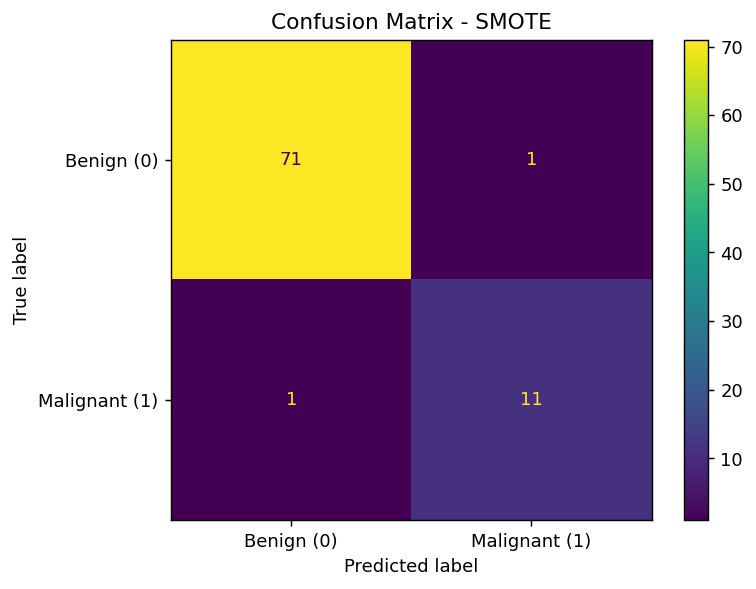

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Benign (0)", "Malignant (1)"]
)
plt.title("Confusion Matrix - " + best_sampling)
plt.show()

### Bước 6. In Classification Report

In [41]:
print(classification_report(
    y_test, y_pred, target_names=["Benign (0)", "Malignant (1)"],
    digits=4, zero_division=0
))

               precision    recall  f1-score   support

   Benign (0)     0.9861    0.9861    0.9861        72
Malignant (1)     0.9167    0.9167    0.9167        12

     accuracy                         0.9762        84
    macro avg     0.9514    0.9514    0.9514        84
 weighted avg     0.9762    0.9762    0.9762        84



### Bước 7. Vẽ Precision–Recall Curve

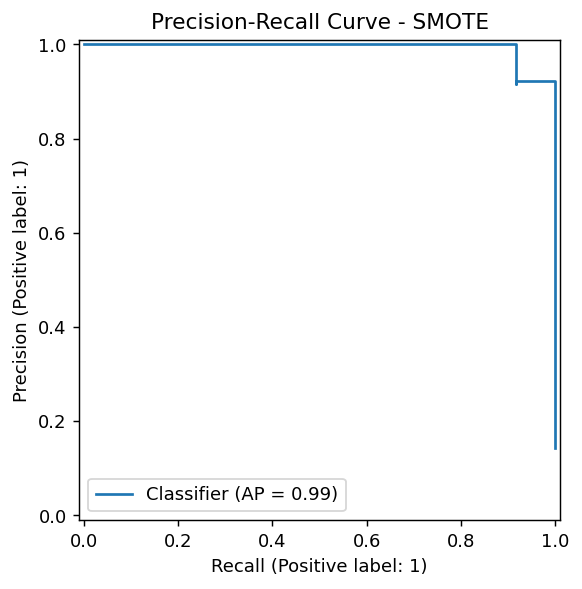

In [42]:
PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision-Recall Curve - " + best_sampling)
plt.show()

**Nhận xét:** SMOTE + Logistic Regression đạt Accuracy 0.9762, Precision/Recall/F1 đều 0.9167 và AP 0.9936 trên Test. Có 71 benign và 11 malignant được nhận diện đúng; 1 benign bị báo động nhầm và 1 malignant bị bỏ sót.